<a href="https://colab.research.google.com/github/zinofiad824-cloud/-ppi-ml-learning/blob/main/MDM2_Residue_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

%pip install -q biopython pandas matplotlib

from Bio.PDB import PDBParser
from Bio.PDB.Polypeptide import is_aa
from Bio.SeqUtils import seq1

from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import matplotlib.pyplot as plt

project = Path("week02_mdm2_structure")

raw_folder = project / "data" / "raw"
processed_folder = project / "data" / "processed"
results_folder = project / "results"

for folder in [raw_folder, processed_folder, results_folder]:
    folder.mkdir(parents=True, exist_ok=True)

pdb_file = raw_folder / "1YCR.pdb"

url = "https://files.rcsb.org/download/1YCR.pdb"

urlretrieve(url, pdb_file)

parser = PDBParser(QUIET=True)

structure = parser.get_structure("1YCR", str(pdb_file))

model = structure[0]

print("Structure loaded successfully.")
print("Chains:", [chain.id for chain in model])


Structure loaded successfully.
Chains: ['A', 'B']


In [2]:

mdm2_chain = model["A"]

p53_chain = model["B"]

print("MDM2 chain:", mdm2_chain.id)

print("p53 chain:", p53_chain.id)


MDM2 chain: A
p53 chain: B


In [3]:

for residue in p53_chain:

    if is_aa(residue, standard=True):

        residue_number = residue.id[1]

        residue_name = residue.resname

        print(residue_number, residue_name)


17 GLU
18 THR
19 PHE
20 SER
21 ASP
22 LEU
23 TRP
24 LYS
25 LEU
26 LEU
27 PRO
28 GLU
29 ASN


In [4]:

phe19 = p53_chain[19]

print("Residue name:", phe19.resname)

print("Residue identifier:", phe19.id)


Residue name: PHE
Residue identifier: (' ', 19, ' ')


In [5]:

for atom in phe19:

    print(
        atom.name,
        atom.element,
        atom.coord
    )


N N [ 32.143 -27.542 -11.625]
CA C [ 31.769 -26.453 -10.742]
C C [ 30.344 -26.019 -10.974]
O O [ 29.549 -25.992 -10.043]
CB C [ 32.674 -25.245 -10.916]
CG C [ 32.265 -24.076 -10.062]
CD1 C [ 32.438 -24.116  -8.685]
CD2 C [ 31.667 -22.955 -10.628]
CE1 C [ 32.021 -23.055  -7.889]
CE2 C [ 31.246 -21.888  -9.839]
CZ C [ 31.421 -21.935  -8.468]


In [7]:

important_residues = {
    "F19": 19,
    "W23": 23,
    "L26": 26
}

for label, number in important_residues.items():

    residue = p53_chain[number]

    print(
        label,
        "| Name:", residue.resname,
        "| Atoms:", len(list(residue.get_atoms()))
    )

assert p53_chain[19].resname == "PHE"

assert p53_chain[23].resname == "TRP"

assert p53_chain[26].resname == "LEU"

print("All three key residues were identified correctly.")



F19 | Name: PHE | Atoms: 11
W23 | Name: TRP | Atoms: 14
L26 | Name: LEU | Atoms: 8
All three key residues were identified correctly.


In [8]:

residue_data = []

for residue in p53_chain:

    if is_aa(residue, standard=True):

        residue_data.append({
            "Chain": p53_chain.id,
            "Residue_number": residue.id[1],
            "Residue_name": residue.resname,
            "One_letter": seq1(residue.resname),
            "Atom_count": len(list(residue.get_atoms()))
        })

residue_df = pd.DataFrame(residue_data)

display(residue_df)




,Chain,Residue_number,Residue_name,One_letter,Atom_count
0,B,17,GLU,E,9
1,B,18,THR,T,7
2,B,19,PHE,F,11
3,B,20,SER,S,6
4,B,21,ASP,D,8
5,B,22,LEU,L,8
6,B,23,TRP,W,14
7,B,24,LYS,K,9
8,B,25,LEU,L,8
9,B,26,LEU,L,8


In [9]:

coordinate_data = []

for residue in p53_chain:

    if is_aa(residue, standard=True) and "CA" in residue:

        ca_atom = residue["CA"]

        x, y, z = ca_atom.coord

        coordinate_data.append({
            "Residue_number": residue.id[1],
            "Amino_acid": seq1(residue.resname),
            "X": x,
            "Y": y,
            "Z": z
        })

coordinates_df = pd.DataFrame(coordinate_data)

display(coordinates_df.round(3))


,Residue_number,Amino_acid,X,Y,Z
0,17,E,31.205999,-33.198002,-11.326
1,18,T,31.948000,-29.737000,-12.658
2,19,F,31.768999,-26.452999,-10.742
3,20,S,28.702999,-25.237000,-12.606
4,21,D,26.813999,-28.452000,-11.882
5,22,L,27.753000,-28.274000,-8.217
6,23,W,27.021000,-24.552999,-7.803
7,24,K,23.530001,-24.716000,-9.231
8,25,L,22.485001,-27.035000,-6.394
9,26,L,22.615999,-24.202000,-3.862


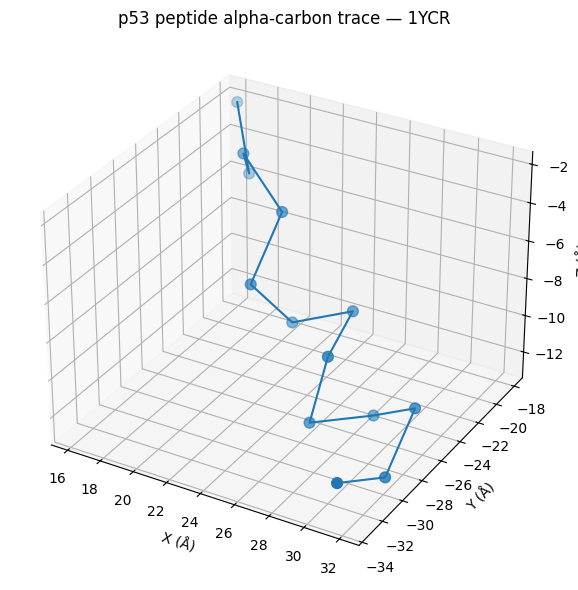

In [10]:

fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    coordinates_df["X"],
    coordinates_df["Y"],
    coordinates_df["Z"],
    s=60
)

ax.plot(
    coordinates_df["X"],
    coordinates_df["Y"],
    coordinates_df["Z"]
)

ax.set_xlabel("X (Å)")
ax.set_ylabel("Y (Å)")
ax.set_zlabel("Z (Å)")

ax.set_title("p53 peptide alpha-carbon trace — 1YCR")

plt.tight_layout()

plt.savefig(
    results_folder / "p53_ca_trace.png",
    dpi=300
)

plt.show()


In [11]:

residue_df.to_csv(
    processed_folder / "1YCR_p53_residues.csv",
    index=False
)

coordinates_df.to_csv(
    processed_folder / "1YCR_p53_ca_coordinates.csv",
    index=False
)

print("Both datasets saved successfully.")


Both datasets saved successfully.


In [12]:

from google.colab import files

files.download(
    str(processed_folder / "1YCR_p53_residues.csv")
)

files.download(
    str(processed_folder / "1YCR_p53_ca_coordinates.csv")
)

files.download(
    str(results_folder / "p53_ca_trace.png")
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>